In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Matplotlib is building the font cache; this may take a moment.


In [3]:
data = {
    'Order_ID': [101, 102, 103, 104, 105, 106, 107, 108],
    'Product': ['Laptop', 'Mobile', 'Tablet', 'Laptop', 'Mobile',
                'Tablet', 'Laptop', 'Mobile'],
    'Category': ['Electronics', 'Electronics', 'Electronics',
                 'Electronics', 'Electronics', 'Electronics',
                 'Electronics', 'Electronics'],
    'Quantity': [2, 3, 1, 2, 4, 2, 1, 3],
    'Price': [50000, 20000, 15000, 50000, 20000, 15000, 50000, 20000],
    'Region': ['North', 'South', 'East', 'West', 'North',
               'South', 'East', 'West']
}

df = pd.DataFrame(data)

# Save data in different formats
df.to_csv('sales.csv', index=False)
df.to_excel('sales.xlsx', index=False)
df.to_json('sales.json', orient='records', indent=4)

print("Sales datasets created successfully!")

Sales datasets created successfully!


In [4]:
# Load CSV file
csv_data = pd.read_csv('sales.csv')

# Load Excel file
excel_data = pd.read_excel('sales.xlsx')

# Load JSON file
json_data = pd.read_json('sales.json')

print("CSV Data:")
print(csv_data)

print("\nExcel Data:")
print(excel_data)

print("\nJSON Data:")
print(json_data)

CSV Data:
   Order_ID Product     Category  Quantity  Price Region
0       101  Laptop  Electronics         2  50000  North
1       102  Mobile  Electronics         3  20000  South
2       103  Tablet  Electronics         1  15000   East
3       104  Laptop  Electronics         2  50000   West
4       105  Mobile  Electronics         4  20000  North
5       106  Tablet  Electronics         2  15000  South
6       107  Laptop  Electronics         1  50000   East
7       108  Mobile  Electronics         3  20000   West

Excel Data:
   Order_ID Product     Category  Quantity  Price Region
0       101  Laptop  Electronics         2  50000  North
1       102  Mobile  Electronics         3  20000  South
2       103  Tablet  Electronics         1  15000   East
3       104  Laptop  Electronics         2  50000   West
4       105  Mobile  Electronics         4  20000  North
5       106  Tablet  Electronics         2  15000  South
6       107  Laptop  Electronics         1  50000   East
7       

In [5]:
# Display first five records
print(df.head())

# Display dataset information
print(df.info())

# Display statistical summary
print(df.describe())

# Check missing values
print(df.isnull().sum())

# Check duplicate records
print(df.duplicated().sum())

   Order_ID Product     Category  Quantity  Price Region
0       101  Laptop  Electronics         2  50000  North
1       102  Mobile  Electronics         3  20000  South
2       103  Tablet  Electronics         1  15000   East
3       104  Laptop  Electronics         2  50000   West
4       105  Mobile  Electronics         4  20000  North
<class 'pandas.DataFrame'>
RangeIndex: 8 entries, 0 to 7
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   Order_ID  8 non-null      int64
 1   Product   8 non-null      str  
 2   Category  8 non-null      str  
 3   Quantity  8 non-null      int64
 4   Price     8 non-null      int64
 5   Region    8 non-null      str  
dtypes: int64(3), str(3)
memory usage: 516.0 bytes
None
        Order_ID  Quantity         Price
count    8.00000  8.000000      8.000000
mean   104.50000  2.250000  30000.000000
std      2.44949  1.035098  16690.459208
min    101.00000  1.000000  15000.000000
25%    102.7

In [6]:
# Remove duplicate records
df = df.drop_duplicates()

# Handle missing values
df = df.fillna({
    'Quantity': 0,
    'Price': 0,
    'Region': 'Unknown'
})

# Remove invalid records
df = df[(df['Quantity'] > 0) & (df['Price'] > 0)]

print("Data after cleaning:")
print(df)

Data after cleaning:
   Order_ID Product     Category  Quantity  Price Region
0       101  Laptop  Electronics         2  50000  North
1       102  Mobile  Electronics         3  20000  South
2       103  Tablet  Electronics         1  15000   East
3       104  Laptop  Electronics         2  50000   West
4       105  Mobile  Electronics         4  20000  North
5       106  Tablet  Electronics         2  15000  South
6       107  Laptop  Electronics         1  50000   East
7       108  Mobile  Electronics         3  20000   West


In [7]:
# Combine all datasets
combined_data = pd.concat(
    [csv_data, excel_data, json_data],
    ignore_index=True
)

# Remove duplicate records
combined_data = combined_data.drop_duplicates()

print("Unified Dataset:")
print(combined_data)

Unified Dataset:
   Order_ID Product     Category  Quantity  Price Region
0       101  Laptop  Electronics         2  50000  North
1       102  Mobile  Electronics         3  20000  South
2       103  Tablet  Electronics         1  15000   East
3       104  Laptop  Electronics         2  50000   West
4       105  Mobile  Electronics         4  20000  North
5       106  Tablet  Electronics         2  15000  South
6       107  Laptop  Electronics         1  50000   East
7       108  Mobile  Electronics         3  20000   West


In [8]:
# Create Total Sales column
df['Total_Sales'] = df['Quantity'] * df['Price']

# Convert product names to uppercase
df['Product'] = df['Product'].str.upper()

# Display transformed data
print(df)

   Order_ID Product     Category  Quantity  Price Region  Total_Sales
0       101  LAPTOP  Electronics         2  50000  North       100000
1       102  MOBILE  Electronics         3  20000  South        60000
2       103  TABLET  Electronics         1  15000   East        15000
3       104  LAPTOP  Electronics         2  50000   West       100000
4       105  MOBILE  Electronics         4  20000  North        80000
5       106  TABLET  Electronics         2  15000  South        30000
6       107  LAPTOP  Electronics         1  50000   East        50000
7       108  MOBILE  Electronics         3  20000   West        60000


In [9]:
total_sales = df['Total_Sales'].sum()

print("Total Sales:", total_sales)

Total Sales: 495000


In [10]:
average_sales = df['Total_Sales'].mean()

print("Average Order Value:", average_sales)

Average Order Value: 61875.0


In [11]:
product_sales = df.groupby('Product')['Total_Sales'].sum()

print("Sales by Product:")
print(product_sales)

Sales by Product:
Product
LAPTOP    250000
MOBILE    200000
TABLET     45000
Name: Total_Sales, dtype: int64


In [12]:
region_sales = df.groupby('Region')['Total_Sales'].sum()

print("Sales by Region:")
print(region_sales)

Sales by Region:
Region
East      65000
North    180000
South     90000
West     160000
Name: Total_Sales, dtype: int64


In [13]:
category_distribution = df['Category'].value_counts()

print("Category Distribution:")
print(category_distribution)

Category Distribution:
Category
Electronics    8
Name: count, dtype: int64


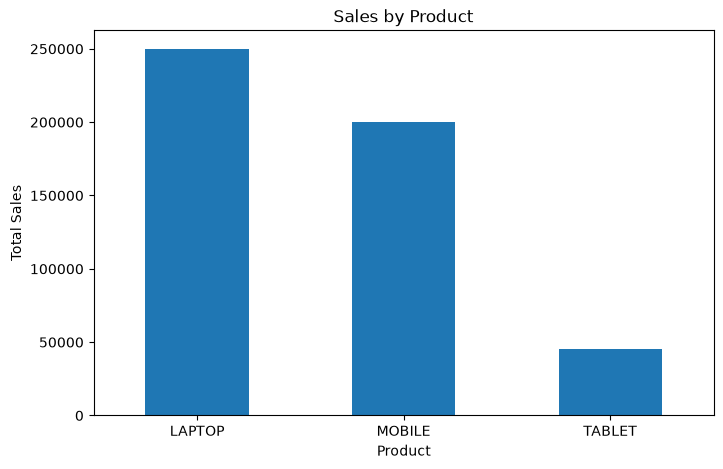

In [14]:
plt.figure(figsize=(8, 5))

product_sales.plot(kind='bar')

plt.title('Sales by Product')
plt.xlabel('Product')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)

plt.show()

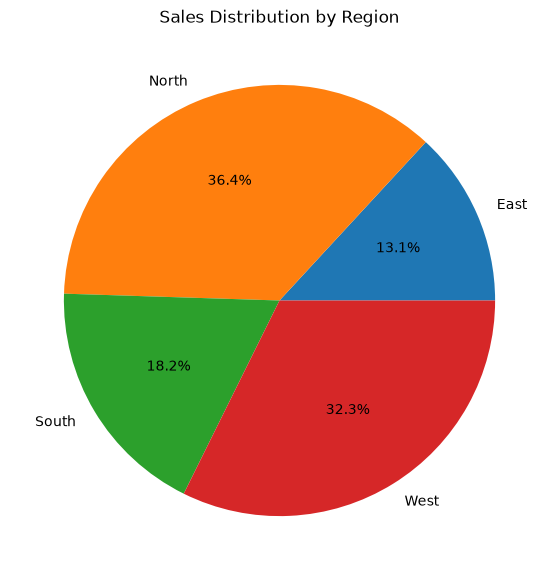

In [15]:
plt.figure(figsize=(7, 7))

region_sales.plot(kind='pie', autopct='%1.1f%%')

plt.title('Sales Distribution by Region')
plt.ylabel('')

plt.show()

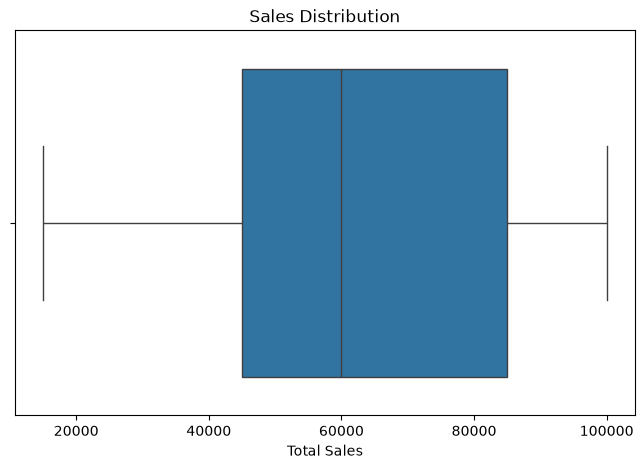

In [16]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=df['Total_Sales'])

plt.title('Sales Distribution')
plt.xlabel('Total Sales')

plt.show()

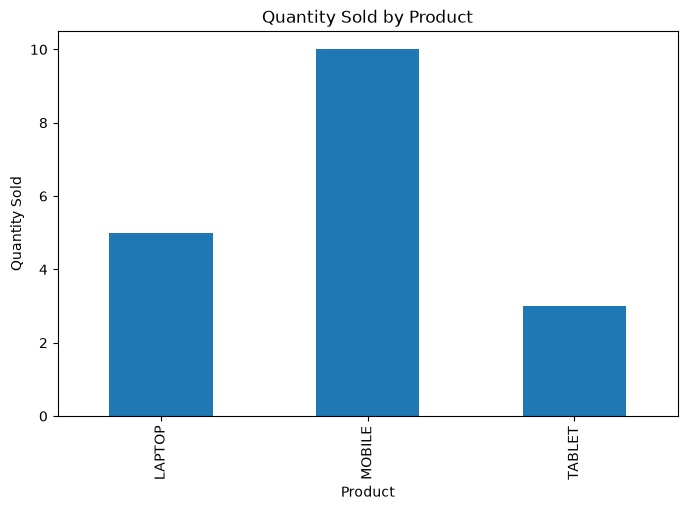

In [17]:
plt.figure(figsize=(8, 5))

df.groupby('Product')['Quantity'].sum().plot(kind='bar')

plt.title('Quantity Sold by Product')
plt.xlabel('Product')
plt.ylabel('Quantity Sold')

plt.show()